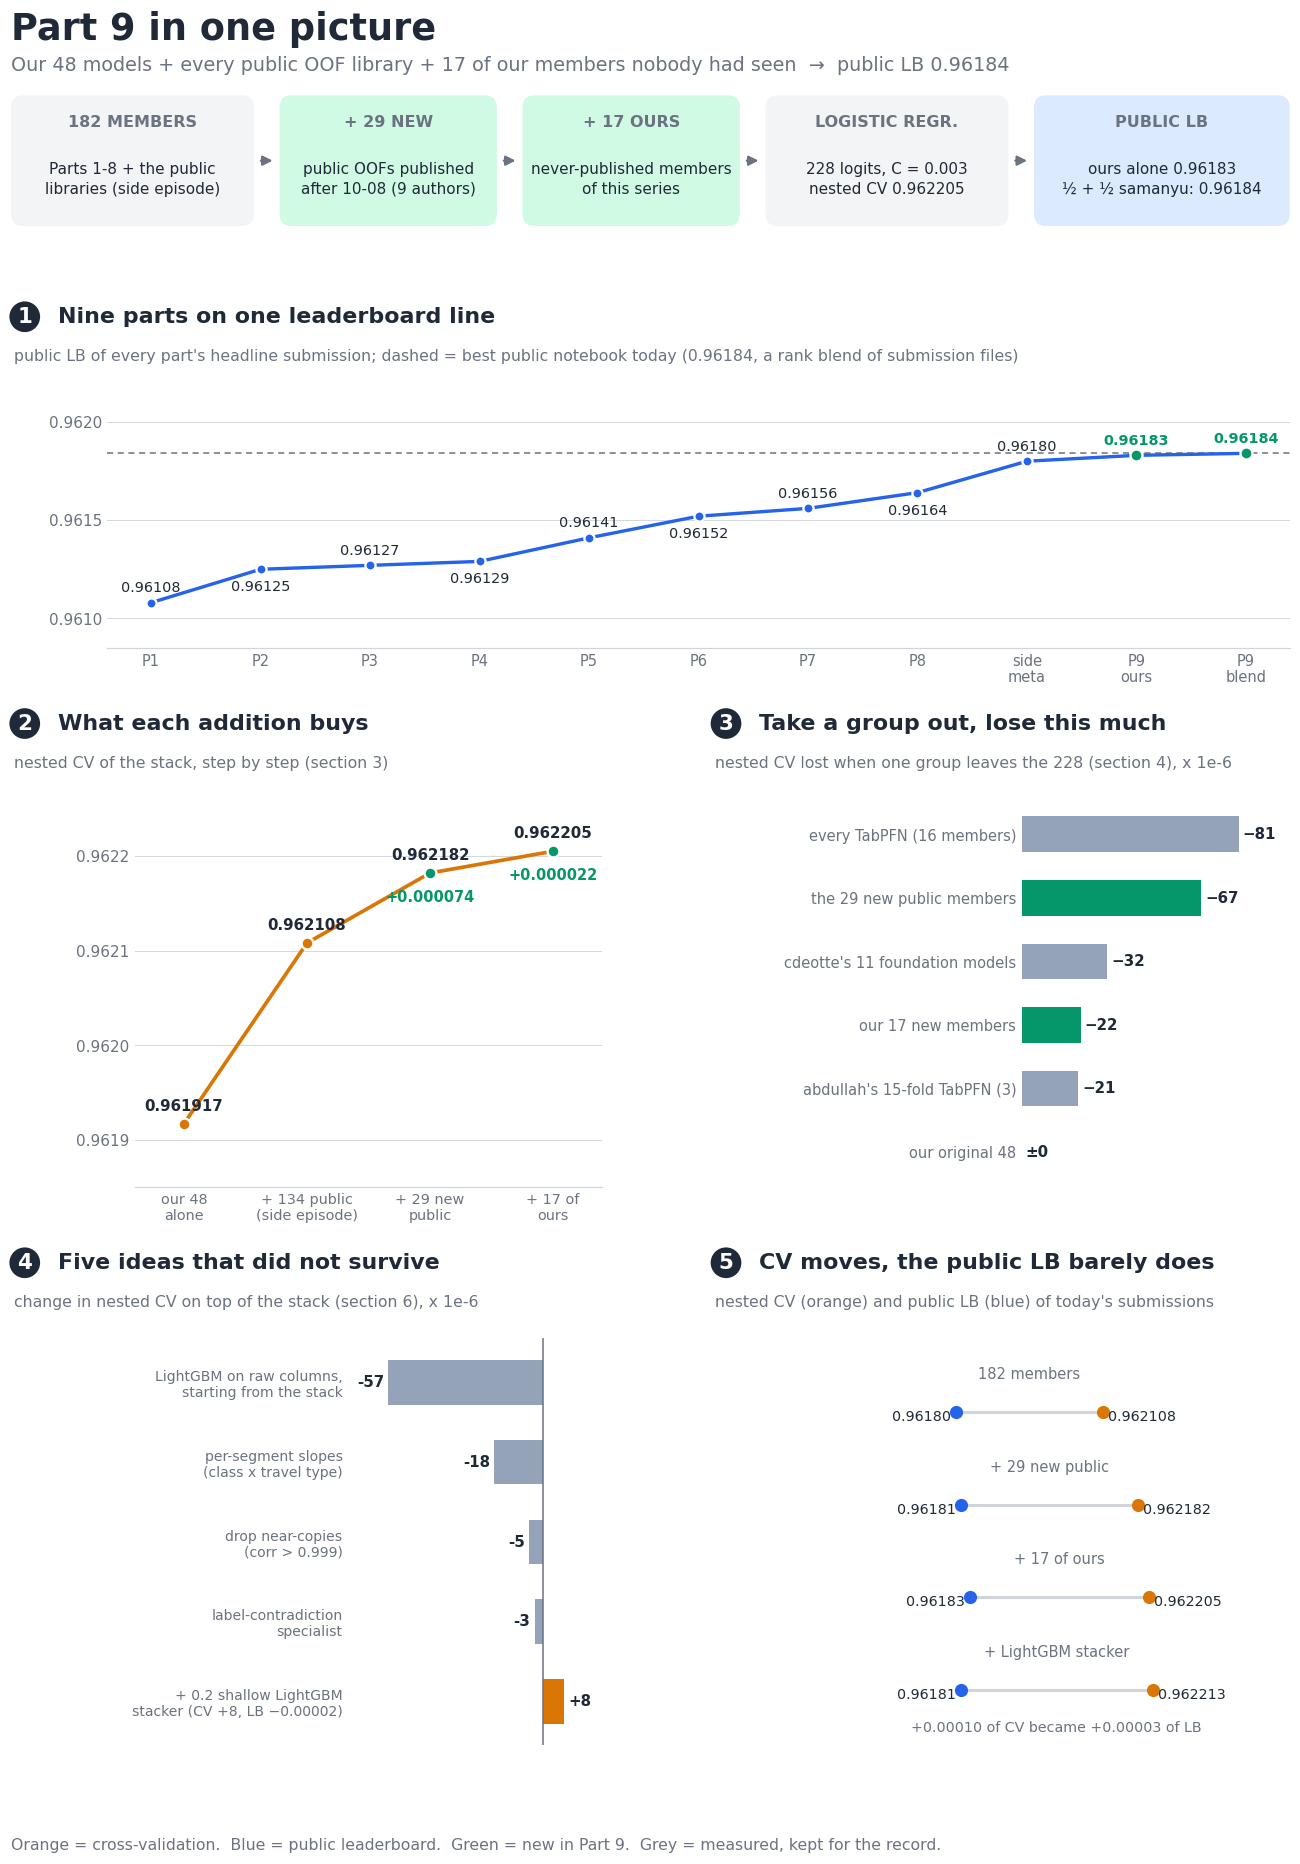

In [1]:
# Part 9 in one picture.  Every number is from our local run of this exact pipeline (nested CV on
# StratifiedKFold(5, shuffle=True, random_state=7)) or from the public leaderboard; the section that
# derives each one is named in the panel.  Nothing is computed by this cell.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

INK, MUTED, RULE, CARD = "#1f2937", "#6b7280", "#d1d5db", "#f3f4f6"
CV, LB, NEW, BAD = "#d97706", "#2563eb", "#059669", "#9ca3af"   # cross-validation / leaderboard / new in Part 9 / no gain
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "text.color": INK,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})
fig = plt.figure(figsize=(12.5, 17.2), dpi=110, facecolor="white")
fig.text(0.04, 0.982, "Part 9 in one picture", fontsize=24, fontweight="bold", va="center")
fig.text(0.04, 0.963, "Our 48 models + every public OOF library + 17 of our members nobody had seen  →  public LB 0.96184",
         fontsize=12.5, color=MUTED, va="center")

# ---------------------------------------------------------------- the pipeline
ax = fig.add_axes([0.04, 0.875, 0.93, 0.075]); ax.set_xlim(0, 100); ax.set_ylim(0, 10); ax.axis("off")
boxes = [(0.0, 19.0, "182 MEMBERS", "Parts 1-8 + the public\nlibraries (side episode)", CARD),
         (21.0, 17.0, "+ 29 NEW", "public OOFs published\nafter 10-08 (9 authors)", "#d1fae5"),
         (40.0, 17.0, "+ 17 OURS", "never-published members\nof this series", "#d1fae5"),
         (59.0, 19.0, "LOGISTIC REGR.", "228 logits, C = 0.003\nnested CV 0.962205", CARD),
         (80.0, 20.0, "PUBLIC LB", "ours alone 0.96183\n½ + ½ samanyu: 0.96184", "#dbeafe")]
for x, w, head, body, col in boxes:
    ax.add_patch(FancyBboxPatch((x, 0.4), w, 9.2, boxstyle="round,pad=0,rounding_size=0.9", fc=col, ec="none"))
    ax.text(x + w / 2, 7.7, head, ha="center", va="center", fontsize=10.5, fontweight="bold", color=MUTED)
    ax.text(x + w / 2, 3.7, body, ha="center", va="center", fontsize=10, linespacing=1.4)
for (x, w, *_), (x2, *_) in zip(boxes[:-1], boxes[1:]):
    ax.add_patch(FancyArrowPatch((x + w + 0.3, 5), (x2 - 0.3, 5), arrowstyle="-|>", mutation_scale=13, color=MUTED, lw=1.5))


def panel(x, y, w, h, pad, no, title, sub):
    fig.text(x, y + h + 0.040, f"{no}", fontsize=14, fontweight="bold", color="white", va="center", ha="center",
             bbox=dict(boxstyle="circle,pad=0.25", fc=INK, ec="none"))
    fig.text(x + 0.024, y + h + 0.040, title, fontsize=14.5, fontweight="bold", va="center")
    fig.text(x - 0.008, y + h + 0.019, sub, fontsize=10.3, color=MUTED, va="center")
    a = fig.add_axes([x + pad, y, w - pad, h])
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        a.spines[s].set_color(RULE)
    a.tick_params(length=0, labelsize=10)
    return a


# ---------------------------------------------------------------- 1. the leaderboard line, nine parts
a = panel(0.05, 0.655, 0.92, 0.135, 0.06, 1, "Nine parts on one leaderboard line",
          "public LB of every part's headline submission; dashed = best public notebook today (0.96184, a rank blend of submission files)")
parts = [("P1", 0.96108), ("P2", 0.96125), ("P3", 0.96127), ("P4", 0.96129), ("P5", 0.96141), ("P6", 0.96152),
         ("P7", 0.96156), ("P8", 0.96164), ("side\nmeta", 0.96180), ("P9\nours", 0.96183), ("P9\nblend", 0.96184)]
xs = range(len(parts))
a.plot(list(xs), [v for _, v in parts], color=LB, lw=2.2, zorder=2)
for i, (lab, v) in enumerate(parts):
    col = NEW if lab.startswith("P9") else LB
    a.scatter([i], [v], s=62 if col == NEW else 44, color=col, zorder=3, edgecolor="white", linewidth=1.5)
    a.text(i, v + 0.000055 if i % 2 == 0 or i > 7 else v - 0.00011, f"{v:.5f}", ha="center", fontsize=9.4,
           color=NEW if col == NEW else INK, fontweight="bold" if col == NEW else "normal")
a.axhline(0.96184, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
a.set_xticks(list(xs)); a.set_xticklabels([p for p, _ in parts], fontsize=9.6, linespacing=1.1)
a.set_ylim(0.96085, 0.96215); a.set_yticks([0.9610, 0.9615, 0.9620]); a.set_xlim(-0.4, len(parts) - 0.6)
a.grid(axis="y", color=RULE, lw=0.6); a.set_axisbelow(True); a.spines["left"].set_visible(False)

# ---------------------------------------------------------------- 2. the ladder
a = panel(0.05, 0.37, 0.42, 0.205, 0.08, 2, "What each addition buys",
          "nested CV of the stack, step by step (section 3)")
labs = ["our 48\nalone", "+ 134 public\n(side episode)", "+ 29 new\npublic", "+ 17 of\nours"]
cv = [0.961917, 0.962108, 0.962182, 0.962205]
cols = [CV, CV, NEW, NEW]
a.plot(range(4), cv, color=CV, lw=2.4, zorder=2)
for i, v in enumerate(cv):
    a.scatter([i], [v], s=60, color=cols[i], zorder=3, edgecolor="white", linewidth=1.5)
    a.text(i, v + 0.000014, f"{v:.6f}", ha="center", fontsize=9.8, color=INK, fontweight="bold")
for i, d in ((2, "+0.000074"), (3, "+0.000022")):
    a.text(i, cv[i] - 0.000030, d, ha="center", fontsize=9.6, color=NEW, fontweight="bold")
a.set_xticks(range(4)); a.set_xticklabels(labs, fontsize=9.4, linespacing=1.2)
a.set_xlim(-0.4, 3.4); a.set_ylim(0.96185, 0.96226)
a.set_yticks([0.9619, 0.9620, 0.9621, 0.9622]); a.grid(axis="y", color=RULE, lw=0.6); a.set_axisbelow(True)
a.spines["left"].set_visible(False)

# ---------------------------------------------------------------- 3. what each group is worth
a = panel(0.56, 0.37, 0.41, 0.205, 0.215, 3, "Take a group out, lose this much",
          "nested CV lost when one group leaves the 228 (section 4), x 1e-6")
grp = [("every TabPFN (16 members)", 81, BAD), ("the 29 new public members", 67, NEW),
       ("cdeotte's 11 foundation models", 32, BAD), ("our 17 new members", 22, NEW),
       ("abdullah's 15-fold TabPFN (3)", 21, BAD), ("our original 48", 0, BAD)]
for i, (lab, v, col) in enumerate(grp):
    a.barh(i, v, height=0.56, color=col if col == NEW else "#94a3b8")
    a.text(v + 1.5, i, f"−{v}" if v else "±0", va="center", fontsize=9.8, color=INK, fontweight="bold")
a.set_yticks(range(len(grp))); a.set_yticklabels([g[0] for g in grp], fontsize=9.6)
a.set_ylim(len(grp) - 0.45, -0.55); a.set_xlim(0, 100); a.set_xticks([])
a.spines["bottom"].set_visible(False); a.spines["left"].set_visible(False)

# ---------------------------------------------------------------- 4. what did not work
a = panel(0.05, 0.075, 0.42, 0.215, 0.235, 4, "Five ideas that did not survive",
          "change in nested CV on top of the stack (section 6), x 1e-6")
bad = [("LightGBM on raw columns,\nstarting from the stack", -57), ("per-segment slopes\n(class x travel type)", -18),
       ("drop near-copies\n(corr > 0.999)", -5), ("label-contradiction\nspecialist", -3),
       ("+ 0.2 shallow LightGBM\nstacker (CV +8, LB −0.00002)", 8)]
for i, (lab, v) in enumerate(bad):
    a.barh(i, v, height=0.56, color=CV if v > 0 else "#94a3b8")
    a.text(v + (1.5 if v > 0 else -1.5), i, f"{v:+d}", va="center", ha="left" if v > 0 else "right",
           fontsize=9.8, color=INK, fontweight="bold")
a.axvline(0, color=MUTED, lw=1)
a.set_yticks(range(len(bad))); a.set_yticklabels([b[0] for b in bad], fontsize=9.2, linespacing=1.15)
a.set_ylim(len(bad) - 0.45, -0.55); a.set_xlim(-72, 22); a.set_xticks([])
a.spines["bottom"].set_visible(False); a.spines["left"].set_visible(False)

# ---------------------------------------------------------------- 5. CV vs LB
a = panel(0.56, 0.075, 0.41, 0.215, 0.07, 5, "CV moves, the public LB barely does",
          "nested CV (orange) and public LB (blue) of today's submissions")
pts = [("182 members", 0.962108, 0.96180), ("+ 29 new public", 0.962182, 0.96181),
       ("+ 17 of ours", 0.962205, 0.96183), ("+ LightGBM stacker", 0.962213, 0.96181)]
for i, (lab, c, l) in enumerate(pts):
    a.plot([l, c], [i, i], color=RULE, lw=2, zorder=1)
    a.scatter([c], [i], s=58, color=CV, zorder=3); a.scatter([l], [i], s=58, color=LB, zorder=3)
    a.text(c + 0.00001, i + 0.05, f"{c:.6f}", fontsize=9.3, color=INK, va="center")
    a.text(l - 0.00001, i + 0.05, f"{l:.5f}", fontsize=9.3, color=INK, va="center", ha="right")
    a.text((c + l) / 2, i - 0.36, lab, fontsize=9.6, color=MUTED, ha="center")
a.set_ylim(3.6, -0.8); a.set_xlim(0.96152, 0.96250); a.set_yticks([]); a.set_xticks([])
a.spines["left"].set_visible(False); a.spines["bottom"].set_visible(False)
a.text(0.96201, 3.45, "+0.00010 of CV became +0.00003 of LB",
       fontsize=9.3, color=MUTED, ha="center")

fig.text(0.04, 0.022, "Orange = cross-validation.  Blue = public leaderboard.  Green = new in Part 9.  Grey = measured, kept for the record.",
         fontsize=10.3, color=MUTED, va="center")
fig.savefig("part9_summary.png", facecolor="white")
plt.show()

# S6E10 | 228-Member Meta Stack | LB 0.96184

> **Part 9 of a series, published as a new version of Part 8.** [Part 1 (LB 0.96108)](https://www.kaggle.com/code/goodpjw2008/s6e10-route-id-fe-og-model-stack-lb-0-96108) ·
> [Part 2 (0.96125)](https://www.kaggle.com/code/goodpjw2008/s6e10-two-view-gbdt-realmlp-stack-lb-0-96125) ·
> [Part 3 (0.96127)](https://www.kaggle.com/code/goodpjw2008/s6e10-catboost-ctr-glm-margin-xgb-lb-0-96127) ·
> [Part 4 (0.96129)](https://www.kaggle.com/code/goodpjw2008/s6e10-auxiliary-task-features-lb-0-96129) ·
> [Part 5 (0.96141)](https://www.kaggle.com/code/goodpjw2008/s6e10-realmlp-aux-task-features-lb-0-96141) ·
> [Part 6 (0.96152)](https://www.kaggle.com/code/goodpjw2008/s6e10-more-aux-carriers-lb-0-96152) ·
> [Part 7 (0.96156)](https://www.kaggle.com/code/goodpjw2008/s6e10-tabpfn-3-5-member-lb-0-96156) ·
> [Part 8 (0.96160 → 0.96164)](https://www.kaggle.com/code/goodpjw2008/s6e10-228-member-meta-stack-lb-0-96184?scriptVersionId=355094993), TabPFN + route categories: version 1 of this page, with all its training code ·
> [side episode: meta stack on public OOF (0.96180)](https://www.kaggle.com/code/goodpjw2008/s6e10-meta-stack-on-public-oof-lb-0-96180).

> **What you can take from this page**
> - **A loader for 228 OOF columns** from 15 published datasets and notebook outputs (sections 1 – 2): copy the two cells, attach the datasets listed in the credits, and you have the whole public pool as one matrix, with row order checked.
> - **17 members nobody else has**: [our new dataset](https://www.kaggle.com/datasets/goodpjw2008/s6e10-goodpjw2008-extra-members-oof). They add +0.000022 to the full public pool (5 of 5 folds).
> - **What each group is worth** (section 4) and **what not to try** (section 6), measured on the same nested folds.
> - **Two submission files**: `submission_ours_228.csv` (LB 0.96183) and `submission.csv` (LB 0.96184).

**What you just saw.** Parts 1 – 8 trained 48 models from scratch and reached LB 0.96164. Our side
episode showed that one logistic regression over the community's published out-of-fold (OOF)
predictions reaches 0.96180. Part 9 asks what is left after that, and answers with three things:

1. **29 public members published after 10-08** (nine authors), found, checked for row order and fold
   discipline, and de-duplicated against the 182 we already had: **+0.000074** nested CV.
2. **17 members of our own series that nobody had seen.** They were rejected by our own 48-model
   stack, so we never published them; on top of the public pool every one of them helps
   (4 – 5 of 5 folds), together **+0.000022** (5 of 5 folds). They are in a new dataset
   ([s6e10-goodpjw2008-extra-members-oof](https://www.kaggle.com/datasets/goodpjw2008/s6e10-goodpjw2008-extra-members-oof)).
3. **Measurements**: what each group of the 228 is worth, and five ideas that did not survive.

**Scores, stated exactly.** Our 228-member stack alone: nested CV 0.962205, **public LB 0.96183**.
The file this notebook submits is a 50/50 rank average of that stack with
[samanyu1808's megastack](https://www.kaggle.com/code/samanyu1808/s6e10-megastack-please-upvote)
(`submission_lr_only.csv`, the same kind of stack over 202 members of theirs that are not public):
**public LB 0.96184**. The weight was fixed at ½ before submitting and never tuned on the leaderboard;
that file has no OOF, so the blend's gain cannot be cross-validated — read it as +0.00001 of public LB, no more.


## Scoreboard: Part 8 → Part 9

The technique-by-technique tables of Parts 1 – 8 are unchanged and still in
[version 1 of this page](https://www.kaggle.com/code/goodpjw2008/s6e10-228-member-meta-stack-lb-0-96184?scriptVersionId=355094993) (Part 8), together with all 48 models' training code.
Part 9 adds the meta level. Nested CV = the combiner is scored only on rows its weights never saw
(meta folds `StratifiedKFold(5, shuffle=True, random_state=7)`; the members use seed 42).

| stack | members | nested CV | gain | public LB |
|---|---|---|---|---|
| Part 8: our own models | 48 | 0.961917 (this split) / 0.961933 (Part 8's) | | 0.96164 |
| side episode: + 134 public members (15 sources), C = 0.003 | 182 | 0.962108 | +0.000191 | 0.96180 |
| **+ 29 public members published after 10-08** *(new)* | 211 | 0.962182 | **+0.000074** | 0.96181 |
| **+ 17 of our own, never published** *(new)* | 228 | **0.962205** | **+0.000022** | **0.96183** |
| *for contrast:* 0.8 × LR + 0.2 × shallow LightGBM stacker (rank blend) | 228 | +0.000008 over the LR | | 0.96181 |
| **½ our 228 + ½ samanyu1808's LR-only megastack** (rank average, untuned) | 228 + 202 | — | — | **0.96184** |

### Submission history (every file we submitted, CV vs public LB)

| # | date | what | CV | LB |
|---|---|---|---|---|
| 1 | 10-01 | one XGBoost, raw columns | 0.958763 | 0.95808 |
| 2 | 10-01 | Part 1, 13-model stack | 0.961436 | 0.96108 |
| 5 | 10-01 | Part 2, 21 models | 0.961577 | 0.96125 |
| 6 | 10-02 | Part 3, 26 models | 0.961612 | 0.96127 |
| 7 | 10-02 | Part 4, 29 models | 0.961671 | 0.96129 |
| 8 | 10-02 | Part 5, 32 models | 0.961747 | 0.96141 |
| 10 | 10-03 | Part 6, 38 models | 0.961759 | 0.96147 (Kaggle run 0.96152) |
| 13 | 10-03 | Part 7, + TabPFN-3.5, 42 | 0.961869 | 0.96153 (Kaggle run 0.96156) |
| 19 | 10-04 | Part 8, + route-aware TabPFN / TabICL, 48 | 0.961935 | 0.96160 (Kaggle run 0.96164) |
| 23 | 10-08 | side episode, 182 public members | 0.962110 | 0.96180 |
| 25 | 10-11 | + 29 new public members, 211 | 0.962182 | 0.96181 |
| 26 | 10-11 | + 17 of ours, 228 | 0.962208 | 0.96183 |
| 27 | 10-11 | 228, + 0.2 LightGBM stacker | 0.962216 | 0.96181 |
| 28 | 10-11 | ½ 228 + ½ samanyu1808 LR-only (this notebook) | — | 0.96184 |

CV − LB has stayed between 0.00028 and 0.00037 since Part 1. Today's CV gains (+0.00010) became +0.00003 of
public LB: at this level the public split (about 30% of the test rows) cannot separate the variants.


## Credits and thanks

This notebook is a combiner: almost all of its value is other people's published models. **If it helps
you, please upvote the sources below**, not only this page. Every member keeps its author's prefix.

**Members from the side episode (182, unchanged):**

| Source | Members |
|---|---|
| [Chris Deotte — 124 public OOF collection](https://www.kaggle.com/datasets/cdeotte/s6e10-124-public-oof-and-test-predictions) (a frozen copy of [kratosyan's library](https://www.kaggle.com/code/kratosyan/s6e10-stacking-every-public-oof-library)); inside it: **our 48** (`gp_`), [sachith7](https://www.kaggle.com/code/sachith7/s6e10-what-each-step-was-worth), [megayak](https://www.kaggle.com/code/megayak/s6e10-honest-oof-stack), mitudru, [busyaprime](https://www.kaggle.com/code/busyaprime/s6e10-route-or-distance-both-lb-0-96169), arhancanli12, [thisray](https://www.kaggle.com/code/thisray/s6e10-xgb-realmlp-catboost-lb-0-96123), samanyu1808 + [hemingweb](https://www.kaggle.com/code/hemingweb/s6e10-exp01-tabpfn35-full-context) TabPFN runs, wangxintong111, najiama | 124 |
| [Chris Deotte — TFM predictions](https://www.kaggle.com/datasets/cdeotte/s6e10-tfm-oof-and-test-predictions) (TabPFN-3.5, TabICL-2, Kumo ×2, Mitra-2, LimiX-2, TabFM, EXAONE, Causilo, XGB/RealMLP baselines) | 11 |
| [dariushafshar — golem OOF library](https://www.kaggle.com/datasets/dariushafshar/s6e10-golem-oof-library) | 3 |
| [sadamtorres — artifacts](https://www.kaggle.com/datasets/sadamtorres/ps-s6e10-airline-satisfaction-artifacts) | 38 |
| [amanatar — forge pairs](https://www.kaggle.com/datasets/amanatar/s6e10-forge-own-pairs) | 6 |

**New in Part 9 (29 public members, all base models, no blends):**

| Source | Members kept | What they are |
|---|---|---|
| [abdullahsafwan333 — OOF dataset](https://www.kaggle.com/datasets/abdullahsafwan333/oof-dataset) | 5 (`ab_`) | TabPFN-3.5 catfd10 / raw / te+cnt on **15 folds x 3 seeds** (best single member: 0.961596), CatBoost, XGBoost |
| [koumeimaki — route TFM/NN OOFs](https://www.kaggle.com/datasets/koumeimaki/s6e10-route-tfm-nn-oof) | 7 (`km_`) | TabPFN catfd10, TabICL, TabM, RealMLP, LightGBM/XGB/CatBoost on shared folds, with a model card per member |
| [sachith7 — stack OOF predictions](https://www.kaggle.com/datasets/sachith7/s6e10-stack-oof-predictions) | 2 (`s7_`) | the CPU-strong LightGBM (folds seed 20261003) and an aux-feature XGBoost; the other 22 were already in the 124 |
| [kratosyan — route-ID teacher](https://www.kaggle.com/code/kratosyan/s6e10-xgboost-realmlp-route-id-teacher) | 2 (`kr_`) | 10-fold XGBoost and RealMLP with a route-ID teacher |
| [kagankoral — encodings](https://www.kaggle.com/code/kagankoral/s6e10-encodings-catboost-realmlp-lb-0-961) | 5 (`kg_`) | LightGBM, XGBoost, CatBoost ×2, RealMLP |
| [Vladimir Demidov (yekenot) — RealMLP · PyTabKit](https://www.kaggle.com/code/yekenot/ps-s6-e10-realmlp-pytabkit) | 1 (`yk_`) | the RealMLP recipe our series has used since Part 1 |
| [Hermengardo — single CatBoost](https://www.kaggle.com/code/hermengardo/single-catboost-eda-ps6e10) | 1 (`hm_`) | CatBoost |
| [dmitriykolmikov — CatBoost all-categorical](https://www.kaggle.com/datasets/dmitriykolmikov/s6e10-catboost-all-categorical-oof-and-test) | 1 (`dk_`) | CatBoost with every column categorical |
| [amanatar — original-prior stack v5](https://www.kaggle.com/code/amanatar/s6e10-the-original-prior-stack-v5) | 5 (`av5_`) | base members only; its logit blend, rank blend and LR stack were left out |
| [samanyu1808 — Megastack](https://www.kaggle.com/code/samanyu1808/s6e10-megastack-please-upvote) | final ½ blend | `submission_lr_only.csv`, used only in the last cell |

**Ideas and caveats we borrowed, with thanks:** [yeashusemwal](https://www.kaggle.com/code/yeashusemwal/secrets-to-satisfaction-it-s-stacking)
(LR C = 0.003, meta folds on a different seed, the 0.8 LR + 0.2 LightGBM stacker we re-measured in section 6),
[Chris Deotte](https://www.kaggle.com/code/cdeotte/stacking-tfms-with-public-oof) (logit pass-through convention),
[karttikjangid05](https://www.kaggle.com/code/karttikjangid05/181-of-340-oofs-are-near-copies-lb-0-96184) (near-copy audit, re-measured in section 6),
[dariushafshar](https://www.kaggle.com/code/dariushafshar/s6e10-the-gap-is-3-8-label-noise-not-features) (the label-noise analysis behind the "contradiction specialist" we tried),
[kozykappa](https://www.kaggle.com/code/kozykappa/s6e10-fast-exact-strong-stack-guarded-residual) (residual stacking, and the warning about blend-level OOFs),
[sachith7](https://www.kaggle.com/code/sachith7/s6e10-what-each-step-was-worth) (the early-stopping remark on our members).

**What is ours:** Parts 1 – 8 (48 members), the 17 new members and their dataset, the search and checks
that admitted the 29, and every measurement in sections 3, 4 and 6.


## 1. The 182 members of the side episode

Each column becomes a log-odds vector; columns already published as logits pass through unchanged.

In [2]:
import glob, json, os, time, warnings
import numpy as np, pandas as pd
from joblib import Parallel, delayed
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

INPUT = os.environ.get("INPUT_DIR", "/kaggle/input")
def find(pat, hint):
    hits = sorted(p for p in glob.glob(f"{INPUT}/**/{pat}", recursive=True) if hint in p)
    assert hits, (pat, hint)
    return hits

tr = pd.read_csv(find("train.csv", "playground-series-s6e10")[0])
te = pd.read_csv(find("test.csv", "playground-series-s6e10")[0])
y = tr["satisfaction"].astype(int).values

def logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-15, 1 - 1e-15)
    return np.clip(np.log(p / (1 - p)), -30, 30)
def tologit(v):
    # a column that leaves [0, 1] is already a logit (cdeotte's convention): pass it through
    v = np.asarray(v, dtype=np.float64)
    return v if (v.min() < 0 or v.max() > 1) else logit(v)

names, cols, tcols = [], [], []
def add(name, o, t):
    o, t = np.asarray(o).ravel(), np.asarray(t).ravel()
    assert len(o) == len(y) and len(t) == len(te) and not np.isnan(o).any(), name
    names.append(name); cols.append(tologit(o)); tcols.append(tologit(t))

# ---- the 182 of the side episode (unchanged loader)
for d, tag in ((find("oof_gp_cat_ctr.npy", "124-public")[0], ""), (find("oof_tabfm.npy", "tfm-oof")[0], "tfm_")):
    d = os.path.dirname(d)
    for f in sorted(glob.glob(f"{d}/oof_*.npy")):
        add(tag + os.path.basename(f)[4:-4], np.load(f), np.load(f.replace("oof_", "test_")))
d = os.path.dirname(find("oof_o_tabpfn35.npy", "golem")[0])
for n in ("o_tabpfn35", "p_lgbm_auxev", "q_lgbm_auxev_10fold"):   # 14 of the 17 are already in the 124
    add("gl2_" + n, np.load(f"{d}/oof_{n}.npy"), np.load(f"{d}/test_{n}.npy"))
d = os.path.dirname(find("preds_e1_allcat_cat.npz", "artifacts")[0])
for f in sorted(glob.glob(f"{d}/preds_*.npz")) + sorted(glob.glob(f"{d}/orig_*_pred.npz")):
    z = np.load(f)
    if "oof" in z and "test" in z and len(z["oof"]) == len(y) and not np.isnan(z["oof"]).any():
        add("st_" + os.path.basename(f)[:-4].replace("preds_", ""), z["oof"], z["test"])
d = os.path.dirname(find("oof_forge_cat.npy", "forge")[0])
for f in sorted(glob.glob(f"{d}/oof_forge_*.npy")):
    add("am_" + os.path.basename(f)[4:-4], np.load(f), np.load(f.replace("oof_", "test_")))
N182 = len(names)
print(f"side episode: {N182} members")

side episode: 182 members


## 2. What was published after 10-08, and 17 members of ours

We searched every dataset and notebook output of the competition published since the side episode. A file is admitted when it has one out-of-fold prediction per training row (any fold count), its rows can be matched to `train.csv`, and it is a base model rather than a blend. Of 55 such columns, 26 were exact copies of members we already had (logit correlation 1.0); the 29 below were kept.

In [3]:
# ---- 29 public members published after 10-08.  Rows are matched by id wherever the file carries ids.
def by_id(path, ids, col):
    return pd.read_csv(path).set_index("id").loc[ids, col].values

d = os.path.dirname(find("tabpfn_catfd10_oof.csv", "oof-dataset")[0])                       # abdullahsafwan333
for m in ("cat_v3", "tabpfn_catfd10", "tabpfn_raw", "tabpfn_te_cnt", "xgb_v3"):
    add("ab_" + m, by_id(f"{d}/{m}_oof.csv", tr["id"], "pred"), by_id(f"{d}/{m}_test.csv", te["id"], "pred"))
d = os.path.dirname(find("train_ids_folds.csv", "route-tfm-nn-oof")[0])                     # koumeimaki
assert (pd.read_csv(f"{d}/train_ids_folds.csv")["id"].values == tr["id"].values).all()
assert (pd.read_csv(f"{d}/test_ids.csv")["id"].values == te["id"].values).all()
for m in ("cat_w1", "lgb_w1", "rmlp_f_nc", "tabicl_fdcat_c250k", "tabm_bcd_rc_v2", "tabpfn_catfd10", "xgb_w1"):
    add("km_" + m, np.load(f"{d}/oof_{m}.npy"), np.load(f"{d}/test_{m}.npy"))
d = os.path.dirname(find("lgb_cpu_strong.npz", "stack-oof-predictions")[0])                 # sachith7 (README: file order)
for m in ("lgb_cpu_strong", "xgb_A_auxall"):                     # the other 22 files are already in the 124
    z = np.load(f"{d}/{m}.npz"); add("s7_" + m, z["oof"], z["test"])
for m in ("rmlp_route_ogaux", "xgb_route_ogaux"):                                          # kratosyan, 10-fold
    z = np.load(find(f"{m}.npz", "route-id-teacher")[0]); add("kr_" + m, z["oof"], z["test"])
d = os.path.dirname(find("oof_members.csv", "encodings-catboost-realmlp")[0])               # kagankoral
for m in ("lgb", "xgb", "cat", "cat_allcat", "realmlp"):
    add("kg_" + m, by_id(f"{d}/oof_members.csv", tr["id"], m), by_id(f"{d}/test_members.csv", te["id"], m))
d = os.path.dirname(find("oof_preds.csv", "realmlp-pytabkit")[0])                           # yekenot
add("yk_realmlp", by_id(f"{d}/oof_preds.csv", tr["id"], "satisfaction"), by_id(f"{d}/submission.csv", te["id"], "satisfaction"))
d = os.path.dirname(find("oof_train.npy", "single-catboost-eda")[0])                        # hermengardo
add("hm_cat", np.load(f"{d}/oof_train.npy"), np.load(f"{d}/oof_test.npy"))
d = os.path.dirname(find("oof_cb_cat.npy", "catboost-all-categorical")[0])                  # dmitriykolmikov
add("dk_cbcat", np.load(f"{d}/oof_cb_cat.npy"), np.load(f"{d}/test_cb_cat.npy"))
z = np.load(find("oof_artifacts.npz", "original-prior-stack-v5")[0])                        # amanatar v5
assert (z["y"] == y).all()
for m in ("lgbm_champion", "lgbm_te", "lgbm_te_rows", "xgb_gpu", "catboost_gpu"):            # base members only
    add("av5_" + m, z["oof_" + m], z["test_" + m])
N211 = len(names)

# how new is each of them?  highest logit correlation with any of the 182
Zall = np.column_stack(cols)
C = np.corrcoef(Zall.T)[N182:, :N182].max(1)
print(f"{N211 - N182} new public members; closest correlation with the 182: "
      f"median {np.median(C):.5f}, max {C.max():.6f} ({names[N182 + int(C.argmax())]})")
print(pd.DataFrame({"OOF AUC": [roc_auc_score(y, Zall[:, i]) for i in range(N182, N211)], "max corr to 182": C},
                   index=names[N182:N211]).round(6).sort_values("OOF AUC", ascending=False).to_string())

29 new public members; closest correlation with the 182: median 0.99779, max 0.999783 (kg_realmlp)
                        OOF AUC  max corr to 182
ab_tabpfn_catfd10      0.961596         0.998179
ab_cat_v3              0.961396         0.997280
ab_xgb_v3              0.961377         0.997209
ab_tabpfn_te_cnt       0.961376         0.998845
km_rmlp_f_nc           0.961295         0.998453
km_cat_w1              0.961223         0.997816
yk_realmlp             0.961218         0.998978
km_lgb_w1              0.961198         0.997999
km_xgb_w1              0.961197         0.998289
km_tabpfn_catfd10      0.961178         0.998320
s7_lgb_cpu_strong      0.961083         0.997827
kr_xgb_route_ogaux     0.961039         0.997148
kr_rmlp_route_ogaux    0.961017         0.997473
kg_realmlp             0.960979         0.999783
s7_xgb_A_auxall        0.960916         0.998196
ab_tabpfn_raw          0.960872         0.999478
kg_lgb                 0.960821         0.997788
kg_cat_allcat      

**Our 17.** Members trained during Parts 1 – 8 that our own stack rejected, so they were never published: 10-fold versions of the view-A trees, the generative classifier of Part 4 (P(column | earlier columns, label), AUC only 0.952 but different errors), TabM, a view-B RealMLP, and RealMLP variants. Soft-label and pseudo-label members were left out on purpose (section 6).

In [4]:
# ---- 17 of our own members that were never published (they did not help our own 48-model stack)
d = os.path.dirname(find("members.csv", "goodpjw2008-extra-members")[0])
card = pd.read_csv(f"{d}/members.csv")
for m in card["member"]:
    add("gpx_" + m, np.load(f"{d}/oof_{m}.npy"), np.load(f"{d}/test_{m}.npy"))
Z, ZT = np.column_stack(cols), np.column_stack(tcols)
print(f"{Z.shape[1]} members x {Z.shape[0]:,} OOF rows")
print(card.to_string(index=False))

228 members x 699,635 OOF rows
              member  oof_auc  gain_alone_on_211  folds_up
             xgb_k10 0.961256           0.000011         5
         xgb_d10_k10 0.961258           0.000010         5
             lgb_k10 0.961215           0.000007         5
             cat_aux 0.960937           0.000005         5
             cat_k10 0.961114           0.000005         4
              gen_v1 0.952399           0.000005         4
   realmlp_pub_aux_k 0.960916           0.000005         4
           cat_ctr_k 0.961003           0.000004         4
          tabm_v4aux 0.960466           0.000004         4
          glm6_xgb_k 0.960829           0.000003         4
  realmlp_fa_aux_n16 0.961071           0.000003         4
    realmlp_fa_auxev 0.961055           0.000003         4
   realmlp_fa_aux3_k 0.961072           0.000003         4
          realmlp_vb 0.961150           0.000003         4
            lgb_v3_k 0.961057           0.000003         4
     realmlp_fa_s7_k 0.96

## 3. What each addition buys (nested CV)

In [5]:
# Nested CV: the combiner is scored on rows its weights never saw.  Meta folds use seed 7, a different
# split from the members' own seed-42 folds.  The five fold fits run in parallel.
skf = list(StratifiedKFold(5, shuffle=True, random_state=7).split(Z, y))
def _fold(Zm, a, b, C):
    return b, LogisticRegression(C=C, max_iter=5000).fit(Zm[a], y[a]).decision_function(Zm[b])
def nested(idx, C=0.003):
    Zm, o = Z[:, idx], np.zeros(len(y))
    for b, v in Parallel(n_jobs=min(5, os.cpu_count()))(delayed(_fold)(Zm, a, b, C) for a, b in skf):
        o[b] = v
    return roc_auc_score(y, o), [roc_auc_score(y[b], o[b]) for _, b in skf], o

t0 = time.time()
ours48 = [i for i, n in enumerate(names) if n.startswith("gp_")]
ladder = [("our 48 alone (C = 1)", ours48, 1.0), ("+ 134 public: the side episode", list(range(N182)), 0.003),
          ("+ 29 new public members", list(range(N211)), 0.003), ("+ 17 of our own", list(range(len(names))), 0.003)]
LAD = {}
for label, idx, Cc in ladder:
    s, fs, o = nested(idx, Cc)
    LAD[label] = (s, fs)
    print(f"{label:34s} {len(idx):4d} members   nested CV {s:.6f}   per fold " + " ".join(f"{v:.5f}" for v in fs))
oof_stack = o
s1, f1 = LAD["+ 29 new public members"]; s2, f2 = LAD["+ 17 of our own"]
print(f"\nour 17: {s2 - s1:+.6f}, {sum(b > a for a, b in zip(f1, f2))} of 5 folds up   ({time.time() - t0:.0f}s)")

our 48 alone (C = 1)                 48 members   nested CV 0.961917   per fold 0.96258 0.96145 0.96166 0.96173 0.96217
+ 134 public: the side episode      182 members   nested CV 0.962110   per fold 0.96277 0.96163 0.96185 0.96198 0.96233
+ 29 new public members             211 members   nested CV 0.962182   per fold 0.96285 0.96170 0.96190 0.96210 0.96237
+ 17 of our own                     228 members   nested CV 0.962204   per fold 0.96285 0.96173 0.96192 0.96213 0.96240

our 17: +0.000022, 5 of 5 folds up   (161s)


## 4. Take a group out, lose this much

In [6]:
# Take one group out of the 228 and see how much nested CV it costs.
groups = {"every TabPFN": lambda n: "tabpfn" in n or n.startswith("pfn_"),
          "the 29 new public members": lambda n: n.split("_")[0] in ("ab", "km", "s7", "kr", "kg", "yk", "hm", "dk", "av5"),
          "cdeotte's 11 foundation models": lambda n: n.startswith("tfm_"),
          "abdullah's 15-fold TabPFNs": lambda n: n.startswith("ab_tabpfn"),
          "our 17 new members": lambda n: n.startswith("gpx_"),
          "our original 48": lambda n: n.startswith("gp_")}
for g, f in groups.items():
    keep = [i for i, n in enumerate(names) if not f(n)]
    s, _, _ = nested(keep)
    print(f"without {g:32s} ({len(names) - len(keep):3d} members)  {s:.6f}   cost {(s2 - s) * 1e6:5.1f} x 1e-6")

without every TabPFN                     ( 16 members)  0.962127   cost  77.3 x 1e-6
without the 29 new public members        ( 29 members)  0.962136   cost  67.9 x 1e-6
without cdeotte's 11 foundation models   ( 11 members)  0.962170   cost  33.7 x 1e-6
without abdullah's 15-fold TabPFNs       (  3 members)  0.962181   cost  23.4 x 1e-6
without our 17 new members               ( 17 members)  0.962182   cost  21.8 x 1e-6
without our original 48                  ( 48 members)  0.962207   cost  -2.8 x 1e-6


## 5. Fit on everything, write both files

In [7]:
stack = LogisticRegression(C=0.003, max_iter=5000).fit(Z, y)
w = pd.Series(stack.coef_[0], index=names)
print("largest |weights|:"); print(w.reindex(w.abs().sort_values(ascending=False).index).head(15).round(3).to_string())
print("\nour members among the top 40:", [n for n in w.abs().sort_values(ascending=False).head(40).index if n.startswith("gp")])

own = stack.decision_function(ZT)
pd.DataFrame({"id": te["id"].values, "satisfaction": 1 / (1 + np.exp(-own))}).to_csv("submission_ours_228.csv", index=False)

# final file: 1/2 our stack + 1/2 samanyu1808's LR-only megastack, as ranks (weight fixed in advance, not tuned)
sam = by_id(find("submission_lr_only.csv", "megastack")[0], te["id"], "satisfaction")
r = lambda v: rankdata(v) / len(v)
print(f"\nrank correlation with samanyu1808's file: {np.corrcoef(r(own), r(sam))[0, 1]:.5f}")
sub = pd.DataFrame({"id": te["id"].values, "satisfaction": 0.5 * r(own) + 0.5 * r(sam)})
sub.to_csv("submission.csv", index=False)
print("submission.csv (blend, public LB 0.96184) and submission_ours_228.csv (ours alone, 0.96183) written")
sub.head()

largest |weights|:
tfm_tabfm                  0.231
ab_tabpfn_catfd10          0.213
tfm_limix2                 0.179
tfm_causilo               -0.147
km_rmlp_f_nc               0.107
am_forge_realmlp           0.086
av5_lgbm_champion         -0.085
gl2_q_lgbm_auxev_10fold    0.083
th_realmlp                -0.082
sa_cat_ctr_auxall_k10      0.080
bp_realmlp                 0.080
sa_rmlp_ogx_aux           -0.077
gp_realmlp_pub_s1         -0.076
tfm_kumosmall             -0.075
gpx_cat_aux               -0.072

our members among the top 40: ['gp_realmlp_pub_s1', 'gpx_cat_aux', 'gp_cat_v3', 'gpx_realmlp_pub_aux_k', 'gpx_realmlp_fa_aux_n16', 'gp_realmlp_pub_aux', 'gp_realmlp_pub_s2', 'gpx_tabm_v4aux']

rank correlation with samanyu1808's file: 0.99958
submission.csv (blend, public LB 0.96184) and submission_ours_228.csv (ours alone, 0.96183) written


,id,satisfaction
0,699635,0.528326
1,699636,0.586969
2,699637,0.650538
3,699638,0.466494
4,699639,0.344896


## 6. What did not work (new in Part 9)

Each idea was measured on top of the 211- or 228-member stack with the same nested folds.

| idea | where it came from | result |
|---|---|---|
| LightGBM on the 21 raw columns, boosted *from* the stack's logit (learn what the stack misses) | kozykappa's guarded residual | **−0.000057** (all 5 folds down) |
| one slope and offset per segment (class × travel type, 6 segments) on the stack's logit | ours | −0.000018; class alone −0.000007 — the stack is already calibrated per segment |
| drop near-copies (keep the best of each group with logit correlation > 0.999 / 0.9995 / 0.9999) | karttikjangid05 | −0.000005 / 0.000000 / −0.000004: harmless, not helpful |
| "contradiction specialist": where a model trained only on the original data is ≥ 99% sure, learn when the label disagrees | dariushafshar's label-noise finding | −0.000003; "sure" covers 61 – 77% of rows, not the 2.6% the idea needs |
| 0.8 × LR + 0.2 × shallow LightGBM stacker | yeashusemwal | CV **+0.000008** (5/5 folds) but public LB 0.96183 → 0.96181: not used |
| C = 0.0015 / 0.002 / 0.004 / 0.006 instead of 0.003 | | −0.000008 / −0.000003 / −0.000007 / −0.000010 |
| the 17 own members **plus** our soft-label and pseudo-label members | ours | +0.000003 more, left out: a cross-fitted teacher's labels carry the scored fold's labels into training |
| 50k / 200k-row TabPFN-3.5 context on Apple MPS (to make a bigger TabPFN on a laptop) | | 50k fine; 200k returns AUC 0.5 — numerically broken on MPS, so the TabPFN axis needs a CUDA GPU |

Datasets we opened and could not use: four test-only prediction sets (no OOF, cannot be stacked), the
private 202-member set behind samanyu1808's megastack, and four blend-level OOFs (left out since the side episode).


## 7. What Part 9 taught us

- **The most valuable members are still the TabPFNs.** Removing all 16 costs 0.000081 — more than the
  29 new public members together (0.000067). Abdullah's three 15-fold × 3-seed TabPFNs alone are worth 0.000021,
  about as much as our 17 new members (0.000022): a TabPFN with more context and more seeds is the clearest unexplored axis.
  It needs a CUDA GPU (section 6), so it is the next part's job.
- **Our original 48 are now redundant (removing them changes nested CV by +0.000001).** The public pool contains
  re-implementations of nearly every idea from Parts 1 – 8 (route IDs, original-data models, auxiliary
  features, route-aware TabPFN). Our 17 *unpublished* members are worth 0.000022; the 48
  everyone already has, nothing. Publishing is how a member stops being an edge.
- **A member that does not help one stack can help another.** All 17 were rejected by our own stack
  (−0.000003 to +0.000002 each in Parts 3 – 6) and every one helps the public pool. Screen candidates on
  the stack you will actually submit.
- **The public leaderboard has stopped resolving this race.** +0.00010 of nested CV produced +0.00003
  of public LB; five different stacks today landed between 0.96181 and 0.96184. We kept the stack chosen
  by CV and say exactly what the last +0.00001 is.

If this page saved you time, an upvote helps the series continue, and an upvote on the sources in the credits table helps the people whose models made this possible. Questions and corrections are welcome in the comments.

> **Reproducibility.** The scores in the title and tables are from our local run of this exact code
> (CPU only, no GPU, no internet). Kernel outputs used as inputs are read at their current version, so a
> later re-run can differ in the fifth decimal if an author updates their notebook.
